In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/reviews.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nDuplicate Review Texts:")
print(df["review_text"].duplicated().sum())

Dataset Shape: (10000, 5)

First 5 Rows:


,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10000 non-null  int64
 1   review_text  10000 non-null  str  
 2   sentiment    10000 non-null  str  
 3   category     10000 non-null  str  
 4   source       10000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB

Missing Values:
review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64

Sentiment Distribution:
sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64

Duplicate Review Texts:
9700


sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64


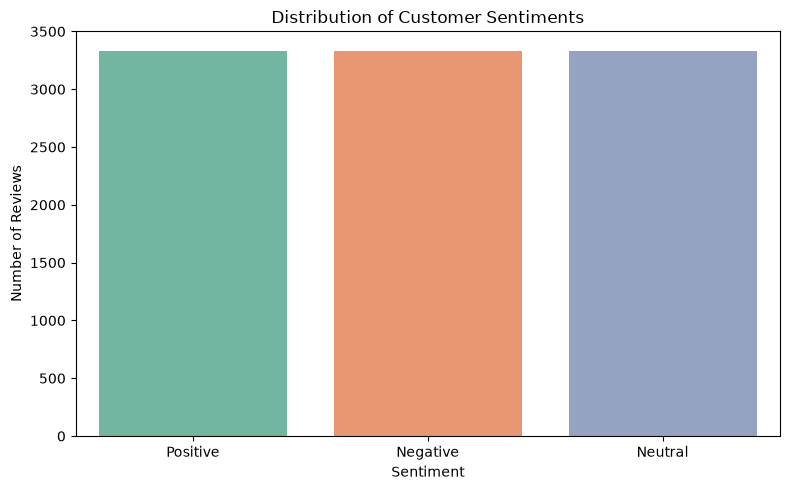

In [33]:
# Count each sentiment class
sentiment_counts = df["sentiment"].value_counts()

print(sentiment_counts)

# Visualize sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sentiment",
    hue="sentiment",
    order=["Positive", "Negative", "Neutral"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

            count       mean       std  min   25%   50%   75%   max
sentiment                                                          
Negative   3333.0  15.465047  3.257330  7.0  15.0  16.0  18.0  21.0
Neutral    3333.0  16.952295  4.143922  7.0  16.0  18.0  20.0  23.0
Positive   3334.0  16.477205  4.169876  7.0  15.0  17.0  19.0  25.0


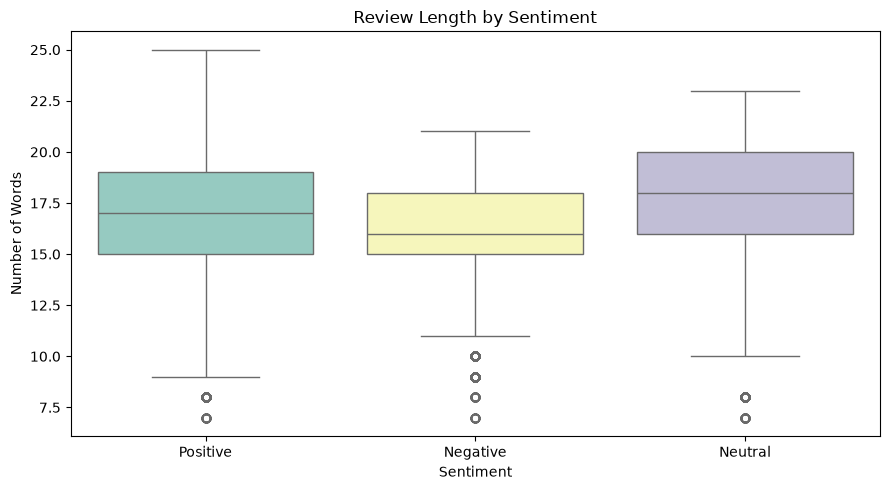

In [34]:
# Calculate review length
df["review_length"] = df["review_text"].str.split().str.len()

print(df.groupby("sentiment")["review_length"].describe())

# Visualize review lengths
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="sentiment",
    y="review_length",
    hue="sentiment",
    order=["Positive", "Negative", "Neutral"],
    palette="Set3",
    legend=False
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()

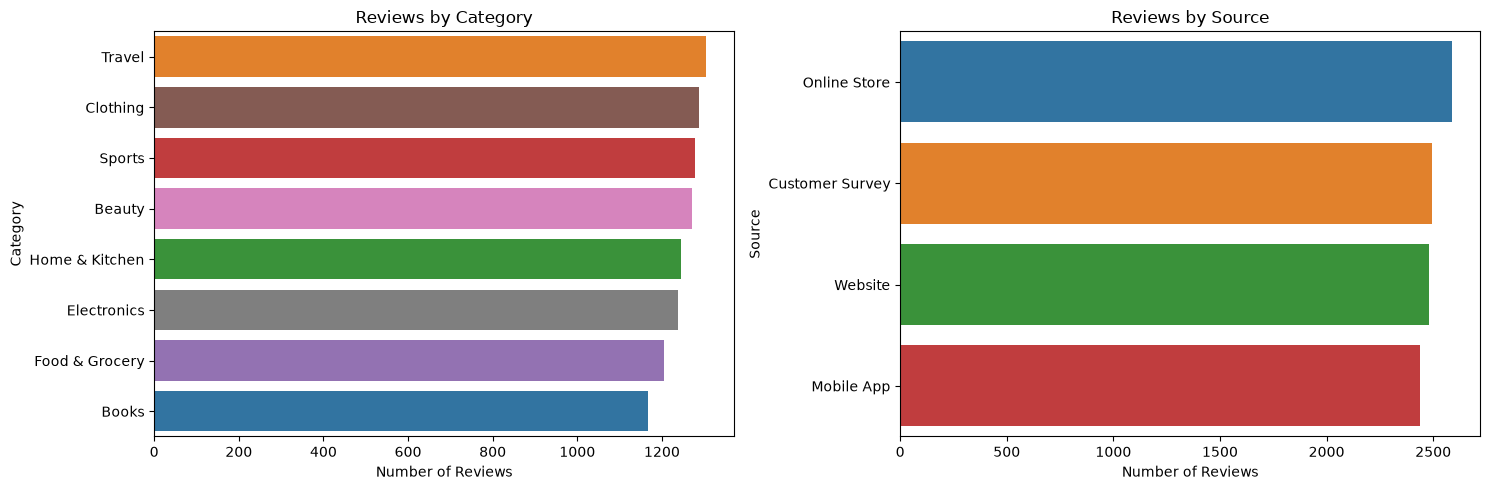

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(
    data=df,
    y="category",
    hue="category",
    order=df["category"].value_counts().index,
    ax=axes[0],
    legend=False
)
axes[0].set_title("Reviews by Category")
axes[0].set_xlabel("Number of Reviews")
axes[0].set_ylabel("Category")

sns.countplot(
    data=df,
    y="source",
    hue="source",
    order=df["source"].value_counts().index,
    ax=axes[1],
    legend=False
)
axes[1].set_title("Reviews by Source")
axes[1].set_xlabel("Number of Reviews")
axes[1].set_ylabel("Source")

plt.tight_layout()
plt.show()

In [36]:
print("Total rows:", len(df))
print("Unique review texts:", df["review_text"].nunique())
print("Repeated text rows:", df["review_text"].duplicated().sum())

# Check whether the same text has conflicting labels
label_counts = df.groupby("review_text")["sentiment"].nunique()

print(
    "Texts with conflicting sentiment labels:",
    (label_counts > 1).sum()
)

# Display the most frequently repeated reviews
print(
    df["review_text"]
    .value_counts()
    .head(10)
)

Total rows: 10000
Unique review texts: 300
Repeated text rows: 9700
Texts with conflicting sentiment labels: 0
review_text
The item is uncomfortable to use and poorly designed. Overall, I am disappointed with the experience.                              52
This product exceeded my expectations in several ways. It has been a good experience so far.                                       48
I would not recommend this product because it caused several problems. Overall, I am disappointed with the experience.             48
I am disappointed with this purchase because the quality is poor. I would not recommend it based on my experience.                 47
Customer support was slow and did not solve my issue. Overall, I am disappointed with the experience.                              46
The order was placed on Monday and delivered on Thursday. I am still evaluating the product.                                       46
The software is slow, unstable, and difficult to use. I would not buy it 

In [37]:
import os

os.makedirs("../data/processed", exist_ok=True)

df.to_csv(
    "../data/processed/reviews_eda.csv",
    index=False
)

print("EDA dataset saved successfully!")

EDA dataset saved successfully!


In [38]:
import re

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", "", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", "", text)

    # Keep letters, digits, and spaces
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
df["cleaned_text"] = df["review_text"].apply(preprocess_text)

# Compare original and cleaned reviews
display(df[["review_text", "cleaned_text", "sentiment"]].head(10))

,review_text,cleaned_text,sentiment
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...,Positive
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...,Negative
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...,Neutral
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...,Negative
4,"The design is simple, attractive, and comforta...",the design is simple attractive and comfortabl...,Positive
5,The delivery was late and the package arrived ...,the delivery was late and the package arrived ...,Negative
6,This is one of the better purchases I have mad...,this is one of the better purchases i have mad...,Positive
7,The product works perfectly and feels well mad...,the product works perfectly and feels well mad...,Positive
8,Customer support responded quickly and solved ...,customer support responded quickly and solved ...,Positive
9,"The service was friendly, efficient, and profe...",the service was friendly efficient and profess...,Positive


In [39]:
print("Original review:")
print(df["review_text"].iloc[0])

print("\nCleaned review:")
print(df["cleaned_text"].iloc[0])

print("\nMissing cleaned texts:")
print(df["cleaned_text"].isna().sum())

print("\nEmpty cleaned texts:")
print(df["cleaned_text"].eq("").sum())

Original review:
This product exceeded my expectations in several ways. It has been a good experience so far.

Cleaned review:
this product exceeded my expectations in several ways it has been a good experience so far

Missing cleaned texts:
0

Empty cleaned texts:
0


In [40]:
df.to_csv(
    "../data/processed/reviews_preprocessed.csv",
    index=False
)

print("Preprocessed dataset saved successfully!")

Preprocessed dataset saved successfully!


In [41]:
import pandas as pd

df = pd.read_csv("../data/processed/reviews_preprocessed.csv")

df["cleaned_text"] = df["cleaned_text"].fillna("").astype(str)
df["sentiment"] = df["sentiment"].astype(str)

X_text = df["cleaned_text"]
y = df["sentiment"]

print("Dataset shape:", df.shape)
print("Number of reviews:", len(X_text))
print("Sentiment classes:", sorted(y.unique()))

Dataset shape: (10000, 7)
Number of reviews: 10000
Sentiment classes: ['Negative', 'Neutral', 'Positive']


In [42]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer(
    max_features=5000,
    ngram_range=(1, 1)
)

X_bow = bow_vectorizer.fit_transform(X_text)

print("BoW matrix shape:", X_bow.shape)
print("Total vocabulary words:", len(bow_vectorizer.vocabulary_))

# Display a small sample
bow_df = pd.DataFrame(
    X_bow[:5].toarray(),
    columns=bow_vectorizer.get_feature_names_out()
)

display(bow_df.iloc[:, :10])

BoW matrix shape: (10000, 266)
Total vocabulary words: 266


,about,accessories,according,adapter,address,advertised,after,afternoon,again,am
0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,1,0
2,0,0,0,1,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0


In [43]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf = tfidf_vectorizer.fit_transform(X_text)

print("TF-IDF matrix shape:", X_tfidf.shape)
print("Total vocabulary features:", len(tfidf_vectorizer.vocabulary_))

TF-IDF matrix shape: (10000, 910)
Total vocabulary features: 910


In [44]:
print("Number of reviews:", len(df))
print("BoW features:", X_bow.shape[1])
print("TF-IDF features:", X_tfidf.shape[1])

print("\nBoW sample:")
print(X_bow[0, :10].toarray())

print("\nTF-IDF sample:")
print(X_tfidf[0, :10].toarray())

Number of reviews: 10000
BoW features: 266
TF-IDF features: 910

BoW sample:
[[0 0 0 0 0 0 0 0 0 0]]

TF-IDF sample:
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [45]:
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit

# Load the preprocessed dataset
df = pd.read_csv("../data/processed/reviews_preprocessed.csv")

df["cleaned_text"] = df["cleaned_text"].fillna("").astype(str)

X = df["cleaned_text"]
y = df["sentiment"]
groups = df["review_text"]

# Keep identical original reviews in the same split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print(
    "Overlapping original review texts:",
    len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
)

Training samples: 7992
Testing samples: 2008
Overlapping original review texts: 0


In [46]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report

experiments = {
    "BoW + Logistic Regression": Pipeline([
        ("vectorizer", CountVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "TF-IDF + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(max_iter=1000))
    ]),

    "BoW + Naive Bayes": Pipeline([
        ("vectorizer", CountVectorizer(
            max_features=5000,
            ngram_range=(1, 2)
        )),
        ("classifier", MultinomialNB())
    ]),

    "TF-IDF + Naive Bayes": Pipeline([
        ("vectorizer", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB())
    ])
}

results = []
trained_models = {}

for name, model in experiments.items():
    print(f"\nTraining: {name}")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions)
    })

    print(classification_report(
        y_test,
        predictions,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

display(results_df)


Training: BoW + Logistic Regression
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       727
     Neutral       1.00      1.00      1.00       761
    Positive       1.00      1.00      1.00       520

    accuracy                           1.00      2008
   macro avg       1.00      1.00      1.00      2008
weighted avg       1.00      1.00      1.00      2008


Training: TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       727
     Neutral       1.00      1.00      1.00       761
    Positive       1.00      1.00      1.00       520

    accuracy                           1.00      2008
   macro avg       1.00      1.00      1.00      2008
weighted avg       1.00      1.00      1.00      2008


Training: BoW + Naive Bayes
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       727
     Neutral       1.00

,Model,Accuracy
0,BoW + Logistic Regression,1.0
1,TF-IDF + Logistic Regression,1.0
2,BoW + Naive Bayes,1.0
3,TF-IDF + Naive Bayes,1.0


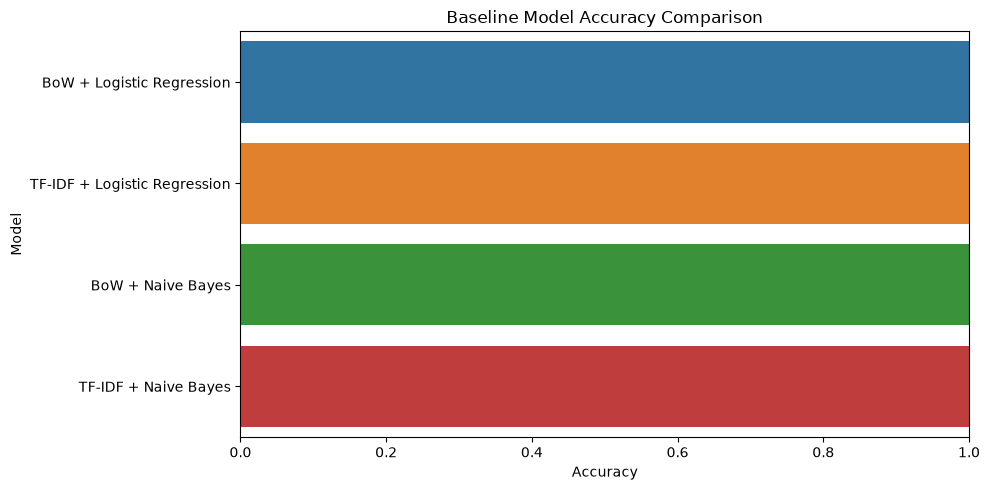

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model",
    hue="Model",
    legend=False
)

plt.title("Baseline Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Best baseline model: BoW + Logistic Regression


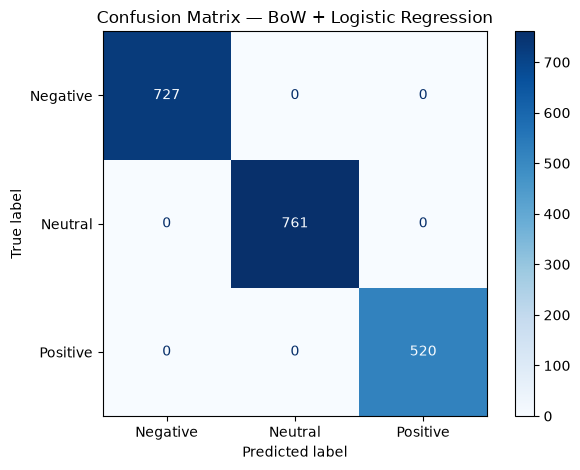

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

best_predictions = best_model.predict(X_test)

print("Best baseline model:", best_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

In [49]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, GroupKFold

# Pipeline prevents vectorizer leakage across folds
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Hyperparameters to test
param_grid = {
    "tfidf__max_features": [3000, 5000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "classifier__C": [0.1, 1, 10]
}

# Keep identical review texts in the same fold
groups_train = df.loc[X_train.index, "review_text"]

cv = GroupKFold(n_splits=5)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train,
    y_train,
    groups=groups_train
)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Macro F1:")
print(grid_search.best_score_)

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Parameters:
{'classifier__C': 10, 'tfidf__max_features': 3000, 'tfidf__ngram_range': (1, 1)}

Best Cross-Validation Macro F1:
1.0


Test Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       727
     Neutral       1.00      1.00      1.00       761
    Positive       1.00      1.00      1.00       520

    accuracy                           1.00      2008
   macro avg       1.00      1.00      1.00      2008
weighted avg       1.00      1.00      1.00      2008



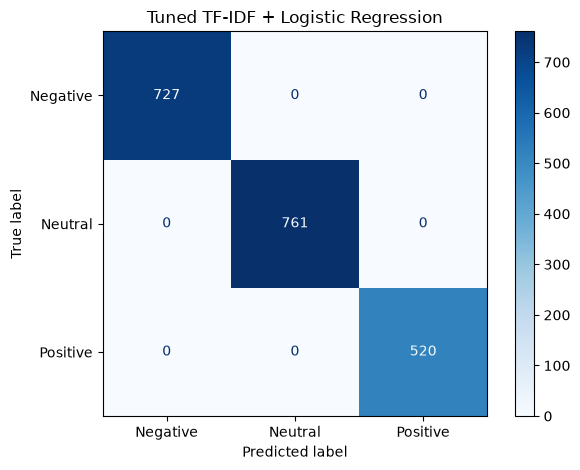

In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

best_model = grid_search.best_estimator_

test_predictions = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=["Negative", "Neutral", "Positive"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    values_format="d"
)

plt.title("Tuned TF-IDF + Logistic Regression")
plt.tight_layout()
plt.show()

In [51]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "../models/sentiment_pipeline.pkl"
)

print("Trained pipeline saved successfully!")

Trained pipeline saved successfully!


In [52]:
import json
import os
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

os.makedirs("../reports", exist_ok=True)

labels = ["Negative", "Neutral", "Positive"]

# Calculate metrics from actual test predictions
report = classification_report(
    y_test,
    test_predictions,
    labels=labels,
    output_dict=True,
    zero_division=0
)

metrics = {
    "test_samples": int(len(y_test)),
    "accuracy": float(
        accuracy_score(y_test, test_predictions)
    ),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"],
    "best_parameters": grid_search.best_params_,
    "best_grouped_cv_macro_f1": float(
        grid_search.best_score_
    )
}

with open(
    "../reports/evaluation_metrics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metrics, f, indent=4)

pd.DataFrame(report).transpose().to_csv(
    "../reports/classification_report.csv"
)

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=labels
)

pd.DataFrame(
    cm,
    index=labels,
    columns=labels
).to_csv("../reports/confusion_matrix.csv")

print(json.dumps(metrics, indent=4))
print("\nEvaluation files saved successfully.")

{
    "test_samples": 2008,
    "accuracy": 1.0,
    "macro_precision": 1.0,
    "macro_recall": 1.0,
    "macro_f1": 1.0,
    "weighted_f1": 1.0,
    "best_parameters": {
        "classifier__C": 10,
        "tfidf__max_features": 3000,
        "tfidf__ngram_range": [
            1,
            1
        ]
    },
    "best_grouped_cv_macro_f1": 1.0
}

Evaluation files saved successfully.
